# 1. Exploratory analysis and descriptive statistics

Before I test anything or fit a model I want to know what the data looks like. This notebook covers both datasets:

- **Bike Sharing** (UCI 275): daily and hourly rental counts from Capital Bikeshare in Washington DC, 2011 to 2012, with weather.
- **Bank Marketing** (UCI 222): phone calls from a Portuguese bank's term deposit campaign, 2008 to 2010. The target is whether the client subscribed.

Most of what I check here changes a decision later, so I note the decision next to each finding.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import SEED
from src.data import load_bank, load_bike_day, load_bike_hour
from src.plotting import PALETTE, save, set_style
from src.stats_utils import iqr_outliers

set_style()
pd.set_option("display.precision", 3)
np.random.seed(SEED)

day = load_bike_day()
hour = load_bike_hour()
bank = load_bank(drop_duration=False)  # keep duration for now so I can show why it goes
print("bike day:", day.shape, " bike hour:", hour.shape, " bank:", bank.shape)

bike day: (731, 17)  bike hour: (17379, 19)  bank: (41188, 22)


## Bike Sharing

The loader converts temperature, humidity and wind back from UCI's 0 to 1 scaling into real units, so the numbers mean something.

In [2]:
day[["cnt", "casual", "registered", "temp_c", "feels_like_c", "humidity", "windspeed"]].describe().T

,count,mean,std,min,25%,50%,75%,max
cnt,731.0,4504.349,1937.211,22.000,3152.000,4548.000,5956.000,8714.000
casual,731.0,848.176,686.622,2.000,315.500,713.000,1096.000,3410.000
registered,731.0,3656.172,1560.256,20.000,2497.000,3662.000,4776.500,6946.000
temp_c,731.0,20.311,7.505,2.424,13.820,20.432,26.872,35.328
feels_like_c,731.0,23.718,8.148,3.953,16.892,24.337,30.430,42.045
humidity,731.0,62.789,14.243,0.000,52.000,62.667,73.021,97.250
windspeed,731.0,12.763,5.192,1.500,9.042,12.125,15.625,34.000


In [3]:
print("missing values in day table:", int(day.isna().sum().sum()))
print("date range:", day["dteday"].min().date(), "to", day["dteday"].max().date())
print("casual + registered == cnt on every row:", bool((day["casual"] + day["registered"] == day["cnt"]).all()))

missing values in day table: 0
date range: 2011-01-01 to 2012-12-31
casual + registered == cnt on every row: True


That last check matters. `casual + registered` adds up to the target exactly, so both columns must stay out of any model that predicts `cnt`. Otherwise the model just learns to add.

### Distributions and skew

Daily totals and hourly counts are the same data at different grain, but their shapes are very different.

In [4]:
skew = pd.Series({
    "daily cnt": day["cnt"].skew(),
    "hourly cnt": hour["cnt"].skew(),
    "daily casual": day["casual"].skew(),
    "hourly cnt, log1p": np.log1p(hour["cnt"]).skew(),
}, name="skewness")
skew.to_frame()

,skewness
daily cnt,-0.047
hourly cnt,1.277
daily casual,1.266
"hourly cnt, log1p",-0.818


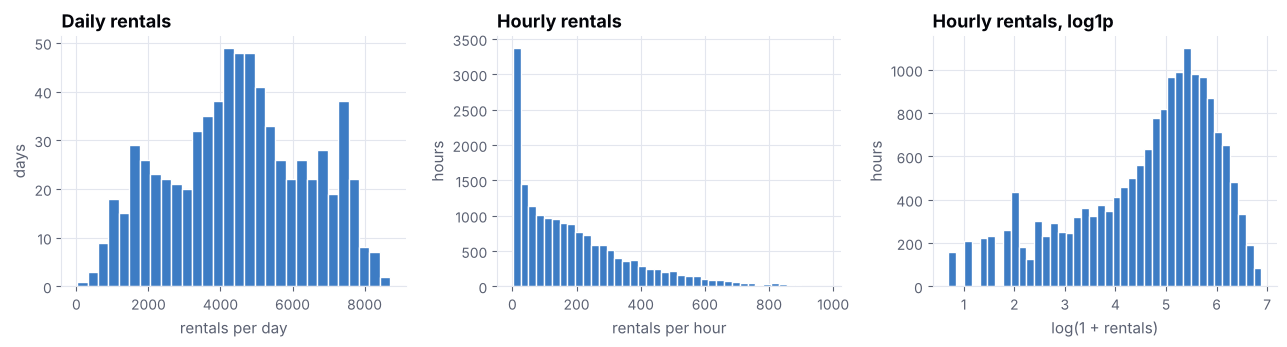

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
axes[0].hist(day["cnt"], bins=30, color=PALETTE[0], edgecolor="white")
axes[0].set(title="Daily rentals", xlabel="rentals per day", ylabel="days")
axes[1].hist(hour["cnt"], bins=40, color=PALETTE[0], edgecolor="white")
axes[1].set(title="Hourly rentals", xlabel="rentals per hour", ylabel="hours")
axes[2].hist(np.log1p(hour["cnt"]), bins=40, color=PALETTE[0], edgecolor="white")
axes[2].set(title="Hourly rentals, log1p", xlabel="log(1 + rentals)", ylabel="hours")
fig.tight_layout()

Daily totals are close to symmetric. Hourly counts are right skewed with a long tail of busy commute hours. The log transform overcorrects a bit (it piles up the quiet night hours on the left), but it does tame the tail. I use `log1p` as the target for the hourly models in notebook 4 for that reason.

### Outliers

I flag points outside 1.5 times the IQR. With skewed data many of these are not errors, just busy hours, so I look before I remove anything.

In [6]:
out = pd.DataFrame({
    "column": ["daily cnt", "hourly cnt", "daily windspeed", "daily humidity"],
    "n_flagged": [iqr_outliers(day["cnt"]).sum(), iqr_outliers(hour["cnt"]).sum(),
                  iqr_outliers(day["windspeed"]).sum(), iqr_outliers(day["humidity"]).sum()],
})
out["share"] = out["n_flagged"] / [len(day), len(hour), len(day), len(day)]
out

,column,n_flagged,share
0,daily cnt,0,0.000
1,hourly cnt,505,0.029
2,daily windspeed,13,0.018
3,daily humidity,2,0.003


In [7]:
day.loc[iqr_outliers(day["humidity"]) | iqr_outliers(day["windspeed"]),
        ["dteday", "humidity", "windspeed", "weather", "cnt"]].sort_values("dteday")

,dteday,humidity,windspeed,weather,cnt
44,2011-02-14,37.583,28.000,clear,1913
49,2011-02-19,18.792,34.000,clear,1635
68,2011-03-10,0.000,17.546,light rain/snow,623
93,2011-04-04,42.625,25.833,clear,3115
94,2011-04-05,64.208,26.000,mist,1795
292,2011-10-20,63.625,28.292,clear,4195
382,2012-01-18,44.333,27.834,clear,3376
407,2012-02-12,46.458,27.417,clear,1529
420,2012-02-25,39.583,28.250,clear,2732
432,2012-03-08,56.750,29.585,clear,5382


The flagged hourly counts are commute peaks, which are the most important hours to get right, so they stay. The windy days are real weather. The humidity of 0 on 2011-03-10, a rainy day, cannot be a real reading and is probably a sensor gap. It is one day out of 731, so I leave it and note it rather than invent a value.

### Hour of day is the big pattern

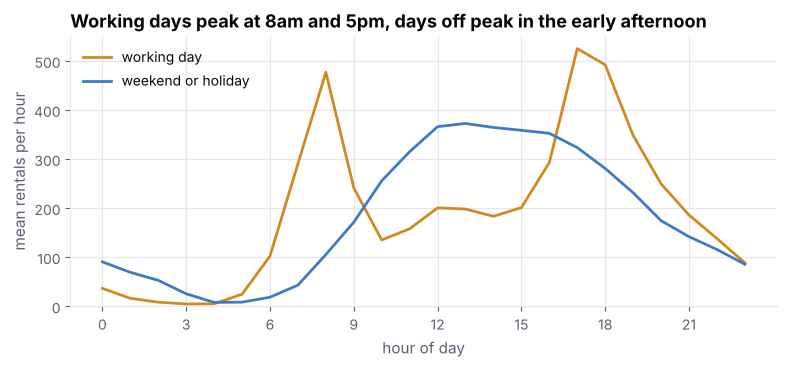

In [8]:
prof = hour.groupby(["workingday", "hr"])["cnt"].mean().unstack(0)
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(prof.index, prof[1], label="working day", color=PALETTE[1])
ax.plot(prof.index, prof[0], label="weekend or holiday", color=PALETTE[0])
ax.set(title="Working days peak at 8am and 5pm, days off peak in the early afternoon",
       xlabel="hour of day", ylabel="mean rentals per hour", xticks=range(0, 24, 3), ylim=(0, None))
ax.legend()
fig.tight_layout()
save(fig, "bike_hourly_profile.png");

Two different shapes: working days have sharp 8am and 5pm commute peaks, weekends have one broad afternoon hump. A linear model with a single "hour" effect cannot represent this unless I give it an hour by working day interaction. Trees find it on their own.

### Correlation

In [9]:
num = day[["cnt", "temp_c", "feels_like_c", "humidity", "windspeed", "yr", "workingday", "holiday"]]
corr = num.corr(method="pearson")
corr.round(2)

,cnt,temp_c,feels_like_c,humidity,windspeed,yr,workingday,holiday
cnt,1.00,0.63,0.63,-0.10,-0.23,0.57,0.06,-0.07
temp_c,0.63,1.00,0.99,0.13,-0.16,0.05,0.05,-0.03
feels_like_c,0.63,0.99,1.00,0.14,-0.18,0.05,0.05,-0.03
humidity,-0.10,0.13,0.14,1.00,-0.25,-0.11,0.02,-0.02
windspeed,-0.23,-0.16,-0.18,-0.25,1.00,-0.01,-0.02,0.01
yr,0.57,0.05,0.05,-0.11,-0.01,1.00,-0.00,0.01
workingday,0.06,0.05,0.05,0.02,-0.02,-0.00,1.00,-0.25
holiday,-0.07,-0.03,-0.03,-0.02,0.01,0.01,-0.25,1.00


In [10]:
spear = num.corr(method="spearman")["cnt"].rename("spearman")
pd.concat([corr["cnt"].rename("pearson"), spear], axis=1).drop("cnt").sort_values("pearson")

,pearson,spearman
windspeed,-0.235,-0.217
humidity,-0.101,-0.098
holiday,-0.068,-0.064
workingday,0.061,0.058
yr,0.567,0.572
temp_c,0.627,0.622
feels_like_c,0.631,0.623


Temperature and feels-like temperature are almost the same variable. That will show up as a huge variance inflation factor in notebook 4, and I will keep only one. Year has a strong positive correlation with rentals because the system grew a lot from 2011 to 2012. Pearson and Spearman agree on the ranking here, so there is nothing badly non-linear hiding in the pairwise view.

## Bank Marketing

In [11]:
print("rows:", len(bank))
bank.head()

rows: 41188


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,pdays,previous,poutcome,emp_var_rate,cons_price_idx,cons_conf_idx,euribor3m,nr_employed,subscribed,previously_contacted
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,NaN,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,0
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,NaN,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,0
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,NaN,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,0
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,NaN,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,0
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,NaN,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,0


In [12]:
rate = bank["subscribed"].mean()
print(f"subscribed: {bank['subscribed'].sum():,} of {len(bank):,} ({rate:.2%})")
print(f"a model that always says 'no' would be {1 - rate:.2%} accurate, which is why accuracy is the wrong metric here")

subscribed: 4,640 of 41,188 (11.27%)
a model that always says 'no' would be 88.73% accurate, which is why accuracy is the wrong metric here


About one call in nine converts. That imbalance drives three choices in notebook 5: stratified splits, PR-AUC alongside ROC-AUC, and a decision threshold picked from costs rather than left at 0.5.

### Missing values are hidden as "unknown"

There are no NaNs in the raw file, but several categorical columns use the string `unknown`, and `pdays` uses 999 for "never contacted".

In [13]:
cat_cols = bank.select_dtypes(exclude="number").columns
unknown = (bank[cat_cols] == "unknown").mean().sort_values(ascending=False)
unknown[unknown > 0].to_frame("share unknown")

,share unknown
default,0.209
education,0.042
housing,0.024
loan,0.024
job,0.008
marital,0.002


In [14]:
print("share never contacted before (pdays was 999):", round(1 - bank["previously_contacted"].mean(), 4))
print("bank['default'] value counts:")
print(bank["default"].value_counts())

share never contacted before (pdays was 999): 0.9632
bank['default'] value counts:
default
no         32588
unknown     8597
yes            3
Name: count, dtype: int64


`default` is almost useless as given: nearly everyone is "no" or "unknown", and only a handful are "yes". I keep `unknown` as its own category instead of dropping rows, since not knowing can itself carry signal.

### Numeric columns, skew and outliers

In [15]:
bnum = ["age", "campaign", "previous", "emp_var_rate", "cons_price_idx", "cons_conf_idx", "euribor3m", "nr_employed", "duration"]
desc = bank[bnum].describe().T
desc["skew"] = bank[bnum].skew()
desc["iqr_outliers"] = [iqr_outliers(bank[c]).sum() for c in bnum]
desc[["mean", "50%", "std", "min", "max", "skew", "iqr_outliers"]]

,mean,50%,std,min,max,skew,iqr_outliers
age,40.024,38.000,10.421,17.000,98.000,0.785,469
campaign,2.568,2.000,2.770,1.000,56.000,4.763,2406
previous,0.173,0.000,0.495,0.000,7.000,3.832,5625
emp_var_rate,0.082,1.100,1.571,-3.400,1.400,-0.724,0
cons_price_idx,93.576,93.749,0.579,92.201,94.767,-0.231,0
cons_conf_idx,-40.503,-41.800,4.628,-50.800,-26.900,0.303,447
euribor3m,3.621,4.857,1.734,0.634,5.045,-0.709,0
nr_employed,5167.036,5191.000,72.252,4963.600,5228.100,-1.044,0
duration,258.285,180.000,259.279,0.000,4918.000,3.263,2963


`campaign` (calls to this client in the current campaign) is very skewed, with a few clients called dozens of times. Tree models do not care, and for logistic regression I scale it. The macro columns (euribor rate, employment) are measured per month, not per client, so they take only a few distinct values.

### Subscription rate by group

In [16]:
def rate_by(col):
    g = bank.groupby(col)["subscribed"].agg(rate="mean", n="size")
    return g.sort_values("rate", ascending=False)

rate_by("poutcome")

,rate,n
poutcome,,
success,0.651,1373
failure,0.142,4252
nonexistent,0.088,35563


In [17]:
rate_by("month")

,rate,n
month,,
mar,0.505,546
dec,0.489,182
sep,0.449,570
oct,0.439,718
apr,0.205,2632
aug,0.106,6178
jun,0.105,5318
nov,0.101,4101
jul,0.090,7174


Clients who said yes to a previous campaign convert at a much higher rate. The month effect is large too, but look at the counts: the high-rate months (March, September, October, December) are also the months with very few calls. That pattern comes from how the campaign was run, so I treat month as a proxy for campaign conditions, not as a seasonal law.

### The `duration` problem

`duration` is the length of the call in seconds.

In [18]:
print(bank.groupby("subscribed")["duration"].median().rename("median call seconds"))
print("calls with duration 0 that subscribed:", int(((bank["duration"] == 0) & (bank["subscribed"] == 1)).sum()))

subscribed
0    163.5
1    449.0
Name: median call seconds, dtype: float64
calls with duration 0 that subscribed: 0


Calls that end in a yes run much longer, because the agent is taking down details. But the duration is only known after the call ends, when the outcome is already known. A model that uses it would look great offline and be useless for deciding who to call. The UCI page says the same thing. I drop it from all models in notebook 5.

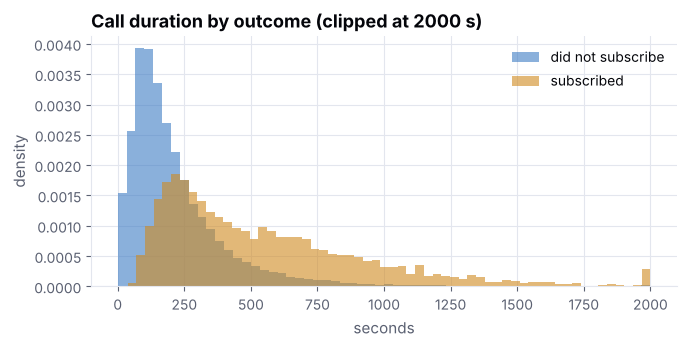

In [19]:
fig, ax = plt.subplots(figsize=(7, 3.6))
for k, label, color in [(0, "did not subscribe", PALETTE[0]), (1, "subscribed", PALETTE[1])]:
    ax.hist(bank.loc[bank["subscribed"] == k, "duration"].clip(upper=2000), bins=60, density=True,
            alpha=0.6, color=color, label=label)
ax.set(title="Call duration by outcome (clipped at 2000 s)", xlabel="seconds", ylabel="density")
ax.legend()
fig.tight_layout()

## What I take forward

- Bike: drop `casual` and `registered` from any model of `cnt`. Use log1p for hourly counts. Expect hour by working day interaction and a strong year trend. Keep only one of the two temperature columns for linear models.
- Bank: 11.27% positive rate, so stratify and use PR-AUC. Keep `unknown` as a category. Drop `duration`. Treat `pdays` through the `previously_contacted` flag.